In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install SimPEG

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 513.9/513.9 kB 11.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 57.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.5/172.5 kB 13.1 MB/s eta 0:00:00
  Created wheel for SimPEG: filename=simpeg-0.25.2-py3-none-any.whl size=595275 sha256=c9c511377a313519d73f9e0b3f58c4ef9e3a6b1d077beb5220c39235e969c4e1
  Stored in directory: /root/.cache/pip/wheels/8a/db/6f/b6da5be3c64674bd3af27db599ff3f633a39e325b67485a2f1
  Created wheel for pymatsolver: filename=pymatsolver-0.4.0-py3-none-any.whl size=15857 sha256=3199c7a293d859db6a1c12e3ce17b8fb5834e68507707c07ff1f51b9

In [3]:
# !pip install pyvista

In [4]:
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt
from simpeg import (
    data,
    data_misfit,
    directives,
    maps,
    inverse_problem,
    optimization,
    inversion,
    regularization,
)

from scipy.spatial import cKDTree

from simpeg.potential_fields import magnetics
from simpeg import utils
from simpeg.utils import mkvc
from discretize.utils import mesh_builder_xyz, refine_tree_xyz, active_from_xyz
from discretize import TensorMesh


In [5]:
import numpy as np
import h5py  # to read data from .mat
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
#import keras.backend as K
import pandas as pd
import os
from scipy.stats import norm
import matplotlib

In [6]:
nc = np.arange(25,2525,50) # column points
nr = np.arange(25,1525,50)*-1 # row points

In [7]:
meshgrid = np.meshgrid(nc,nr)
mesh_pts = np.c_[meshgrid[0].reshape(-1,1),meshgrid[1].reshape(-1,1)]

In [8]:
meshgrid[0].shape

(30, 50)

In [9]:
meshgrid[1].shape

(30, 50)

In [10]:
mesh_pts.shape

(1500, 2)

In [11]:
# Create and array of observation points
xr = np.arange(0, 2500, 50)
zr = np.ones_like(xr)*10
yr = np.zeros_like(xr)
rxLoc = np.c_[mkvc(xr), mkvc(yr), mkvc(zr)]

In [12]:
rxLoc.shape

(50, 3)

In [13]:
x_topo = np.arange(-1000.0, 3501, 50)
y_topo = np.arange(-2500,2501,50)

In [14]:
grid = np.meshgrid(x_topo,y_topo)

In [15]:
topo_grid = np.c_[grid[0].ravel(),grid[1].ravel(),np.zeros_like(grid[0].ravel())]

In [16]:
# We will assume a vertical inducing field
h0_amplitude, h0_inclination, h0_declination = (50000.0, 90.0, 0.0)

# The magnetization is set along a different direction (induced + remanence)
M = np.array([45.0, 90.0])

# # Block with an effective susceptibility
# chi_e = 0.05

In [17]:
# Creating a SimPEG mesh with similar extent as the GemPy model

mesh = TensorMesh(
    [
        [(50,5,-1.5),(50, 50),(50,5,1.5)],
        [(5000, 1)],
        [(50, 30)]
    ]
)
mesh.x0 += [-1000, -2500, -1500]
mesh

TensorMesh: 1,800 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     60     -1,000.00      3,478.12     50.00    379.69    1.50
   y      1     -2,500.00      2,500.00  5,000.00  5,000.00    1.00
   z     30     -1,500.00          0.00     50.00     50.00    1.00

In [19]:
training_model = np.load('/content/drive/MyDrive/STUDY/New/training_model_synth_uniform.npy')

In [20]:
training_model.shape

(30000, 1500)

In [21]:
training_model_recon = np.zeros([training_model.shape[0],len(mesh.cell_centers_x)*len(mesh.cell_centers_z)])

for i in range(training_model.shape[0]):

    density = training_model[i,:]

    tree = cKDTree(mesh_pts)
    _, ind_pad_mesh = tree.query(np.c_[mesh.cell_centers[:,0],mesh.cell_centers[:,2]])
    density_pad = density[ind_pad_mesh]

    training_model_recon[i] = density_pad

In [22]:
ind_pad_mesh.shape

(1800,)

In [23]:
training_model_recon.shape

(30000, 1800)

In [24]:
# Define the active cells from topo
actv = active_from_xyz(mesh, topo_grid)
nC = int(actv.sum())
# Create reduced identity map
idenMap = maps.IdentityMap(nP=nC)

In [25]:
nC

1800

In [26]:
receiver_list = magnetics.receivers.Point(rxLoc, components=["bx", "by", "bz"])
srcField = magnetics.sources.UniformBackgroundField(
    receiver_list=[receiver_list],
    amplitude=h0_amplitude,
    inclination=h0_inclination,
    declination=h0_declination,
)
surveyAmp = magnetics.survey.Survey(srcField)

simulation = magnetics.simulation.Simulation3DIntegral(
    mesh=mesh,
    survey=surveyAmp,
    chiMap=idenMap,
    active_cells=actv,
    is_amplitude_data=True,
)

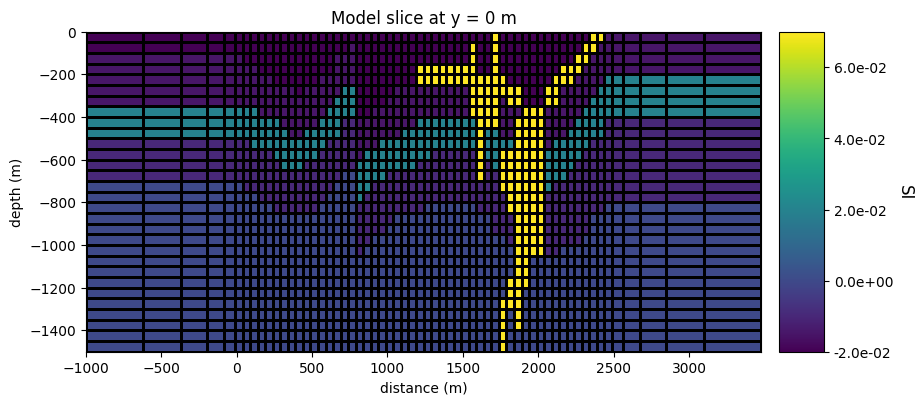

In [27]:
model = training_model_recon[82]
# Plot True Model
fig = plt.figure(figsize=(9, 4))
plotting_map = maps.InjectActiveCells(mesh, actv, np.nan)

ax1 = fig.add_axes([0.08, 0.1, 0.75, 0.8])
mesh.plot_slice(
    plotting_map * model,
    normal="Y",
    ax=ax1,
    ind=int(mesh.shape_cells[1] / 2),
    grid=True,
    clim=(np.min(model), np.max(model)),
    pcolor_opts={"cmap": "viridis"},
)
ax1.set_title("Model slice at y = 0 m")
ax1.set_xlabel('distance (m)')
ax1.set_ylabel('depth (m)')

ax2 = fig.add_axes([0.85, 0.1, 0.05, 0.8])
norm = matplotlib.colors.Normalize(vmin=np.min(model), vmax=np.max(model))
cbar = matplotlib.colorbar.ColorbarBase(
    ax2, norm=norm, orientation="vertical", cmap=matplotlib.cm.viridis, format="%.1e"
)
cbar.set_label("SI", rotation=270, labelpad=15, size=12)


# Displaying the plo

plt.show()

In [28]:
np.max(training_model_recon)

np.float64(0.07000732421875)

In [29]:
np.min(training_model_recon)

np.float64(-0.0200042724609375)

In [30]:
# replace any negative values in training_model_recon with zero
training_model_recon[training_model_recon < 0] = 0

In [31]:
np.min(training_model_recon)

np.float64(0.0)

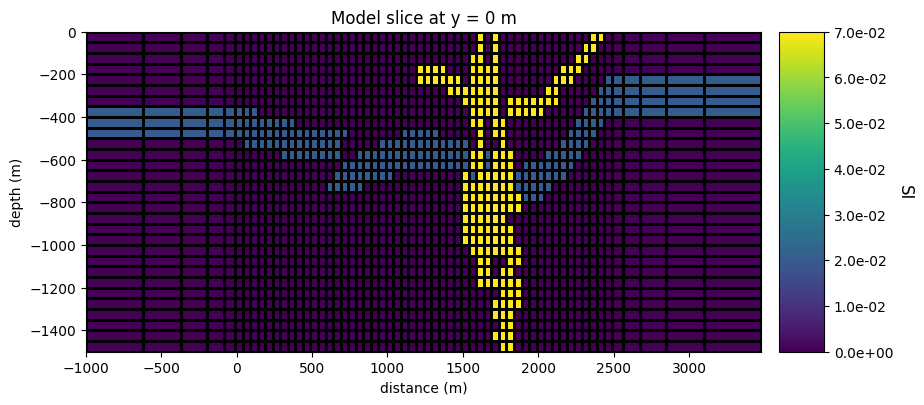

In [32]:
model = training_model_recon[6772]
# Plot True Model
fig = plt.figure(figsize=(9, 4))
plotting_map = maps.InjectActiveCells(mesh, actv, np.nan)

ax1 = fig.add_axes([0.08, 0.1, 0.75, 0.8])
mesh.plot_slice(
    plotting_map * model,
    normal="Y",
    ax=ax1,
    ind=int(mesh.shape_cells[1] / 2),
    grid=True,
    clim=(np.min(model), np.max(model)),
    pcolor_opts={"cmap": "viridis"},
)
ax1.set_title("Model slice at y = 0 m")
ax1.set_xlabel('distance (m)')
ax1.set_ylabel('depth (m)')

ax2 = fig.add_axes([0.85, 0.1, 0.05, 0.8])
norm = matplotlib.colors.Normalize(vmin=np.min(model), vmax=np.max(model))
cbar = matplotlib.colorbar.ColorbarBase(
    ax2, norm=norm, orientation="vertical", cmap=matplotlib.cm.viridis, format="%.1e"
)
cbar.set_label("SI", rotation=270, labelpad=15, size=12)

# Adding details to the plot


# Displaying the plo


plt.show()

In [33]:
min_sus = 0
max_sus = 0.07

In [34]:
training_model_recon_scaled = (training_model_recon-min_sus)/(max_sus - min_sus)

In [35]:
print(np.min(training_model_recon_scaled))
print(np.max(training_model_recon_scaled))

0.0
1.0001046316964284


In [36]:
#training_model_3D = np.zeros((training_model_recon.shape[0],len(mesh.cell_centers_z),len(mesh.cell_centers_x)))
#for i in range(training_model_recon.shape[0]):
#  training_model_3D[i,:,:] = training_model_recon[i,:].reshape(len(mesh.cell_centers_z),len(mesh.cell_centers_x))

In [37]:
#training_model_3D[12,:,:].shape

In [38]:
X_train_model = training_model_recon_scaled[:25000,:]
X_test_model = training_model_recon_scaled[25000:,:]

In [39]:
X_train_model.shape

(25000, 1800)

In [40]:
X_test_model.shape

(5000, 1800)

In [41]:
training_model_recon.shape

(30000, 1800)

In [42]:
training_bamp = np.zeros([training_model.shape[0],len(rxLoc)])

for i in range(training_model_recon.shape[0]):
    model = training_model_recon[i]
    d_pred_tmp = simulation.fields(model)
    training_bamp[i] = d_pred_tmp + np.random.randn(len(rxLoc)) * 50


In [43]:
model.shape

(1800,)

In [44]:
data_covariance_matrix_inv = np.diag(np.square(1/50)*np.ones(len(rxLoc))) # Wd.T*Wd

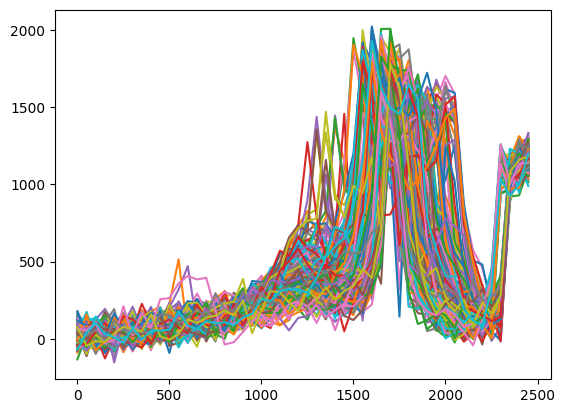

In [45]:
for i in range(training_bamp.shape[0]):
  if i%100==0:
    plt.plot(rxLoc[:,0],training_bamp[i])

In [46]:
X_train_data = training_bamp[:25000,:]
X_test_data = training_bamp[25000:,:]

In [47]:
def cal_Jtvec(m_pred,d_true):
   m_pred = m_pred*0.07  # convert predicted values ranging from 0 to 1, to the real susceptibility values ranging from 0 to 0.07 SI.
   d_res = simulation.fields(m_pred)-d_true   # need to include Wd, i.e., data weighting matrix
   d_res_normalize = np.matmul(data_covariance_matrix_inv,d_res)
   Jtdres = simulation.Jtvec(m_pred,d_res_normalize)   # J: partial mag_amplitude/partial effective_sus
   data_misfit = np.matmul(d_res.T,d_res_normalize)
   return Jtdres, data_misfit

In [48]:
def concatenate_Jtvec(batch_size,decoder_output_model,dtrue_batch):
   Jtdres_batch = np.zeros([batch_size,len(mesh.cell_centers_x)*len(mesh.cell_centers_z)])
   datamisfit_batch = np.zeros(batch_size)
   for i in range(batch_size):
      Jtdres_i,data_misfit = cal_Jtvec(decoder_output_model[i],dtrue_batch[i])
      Jtdres_batch[i] = 0.07*Jtdres_i
      datamisfit_batch[i] = data_misfit
   return Jtdres_batch, datamisfit_batch


In [49]:
coding_size = 300

In [50]:
class Sampling(keras.layers.Layer):
  def call(self,inputs):
    mean, log_var = inputs
    return tf.random.normal(tf.shape(log_var))*tf.exp(log_var/2) + mean

In [51]:
len(mesh.cell_centers_z)

30

In [52]:
encoder_input_model = keras.layers.Input(shape=[len(mesh.cell_centers_z)*len(mesh.cell_centers_x),])
#z = keras.layers.Flatten()(encoder_input_model) # Flaten the input because we will use dense layers for the subsequent layers
z = keras.layers.Dense(1500, activation='relu')(encoder_input_model)
z = keras.layers.Dense(1200, activation='relu')(z)
z = keras.layers.Dense(800, activation = 'relu')(z)
z = keras.layers.Dense(500, activation='relu')(z)
codings_mean = keras.layers.Dense(coding_size)(z)  # mu
codings_log_var = keras.layers.Dense(coding_size)(z) # log_var, i.e., log of variance
codings = Sampling()([codings_mean, codings_log_var])
variational_encoder = keras.Model(inputs=encoder_input_model,outputs=[codings_mean,codings_log_var,codings])

In [53]:
variational_encoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1800)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1500)      │  2,701,500 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1200)      │  1,801,200 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 800)       │    960,800 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 500)       │    400,500 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 300)       │    150,300 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 300)       │    150,300 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 300)       │          0 │ dense_4[0][0],    │
│                     │                   │            │ dense_5[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,164,600 (23.52 MB)

 Trainable params: 6,164,600 (23.52 MB)

 Non-trainable params: 0 (0.00 B)

In [54]:
decoder_input_coding = keras.layers.Input(shape=[coding_size])
decoder_input_data = keras.layers.Input(shape=[len(rxLoc)])  # note that gravity data is the second input into decoder in additon to the coding

decoder_inputs = keras.layers.Concatenate()([decoder_input_coding,decoder_input_data])
x = keras.layers.Dense(500, activation='relu')(decoder_inputs)
x = keras.layers.Dense(800, activation='relu')(x)
x = keras.layers.Dense(1200, activation='relu')(x)
x = keras.layers.Dense(1500, activation='relu')(x)
output_model = keras.layers.Dense(len(mesh.cell_centers_x)*len(mesh.cell_centers_z), activation='sigmoid')(x) # use sigmoid because our desired output is 0 or 1, or between 0 and 1.
#output_model = keras.layers.Reshape([len(mesh.cell_centers_z),len(mesh.cell_centers_x)])(x)  # first output is a 2D density model

variational_decoder = keras.Model(inputs=[decoder_input_coding,decoder_input_data],outputs=output_model)

In [55]:
variational_decoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 300)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 350)       │          0 │ input_layer_1[0]… │
│ (Concatenate)       │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 500)       │    175,500 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 800)       │    400,800 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 1200)      │    961,200 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 1500)      │  1,801,500 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 1800)      │  2,701,800 │ dense_9[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,040,800 (23.04 MB)

 Trainable params: 6,040,800 (23.04 MB)

 Non-trainable params: 0 (0.00 B)

In [56]:
_,_,codings = variational_encoder(encoder_input_model)
decoder_output_model = variational_decoder([codings,decoder_input_data])
variational_ae = keras.Model(inputs=[encoder_input_model],outputs=[decoder_output_model])

In [57]:
variational_ae.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1800)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ [(None, 300),     │  6,164,600 │ input_layer[0][0] │
│ (Functional)        │ (None, 300),      │            │                   │
│                     │ (None, 300)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_1        │ (None, 1800)      │  6,040,800 │ functional[0][2], │
│ (Functional)        │                   │            │ input_layer_2[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,205,400 (46.56 MB)

 Trainable params: 12,205,400 (46.56 MB)

 Non-trainable params: 0 (0.00 B)

Loss function

$L = \alpha_m||\mathbf{m}-\mathbf{m}_{train}||^2 + \alpha_d ||\mathbf{W}_d[f(\mathbf{m})-\mathbf{d}_{train}]||^2 + \alpha_L D_{KL}(N(\mu,\sigma)||N(0,1))$

At each iteration, the gradient is

$\frac{\partial{L}}{\partial{\mathbf{p}}} = \frac{\partial{\mathbf{m}}}{\partial{\mathbf{p}}}\frac{\partial{L}}{\partial{\mathbf{m}}} = \frac{\partial{\mathbf{m}}}{\partial{\mathbf{p}}}[2\alpha_m(\mathbf{m}-\mathbf{m}_{train})+2\alpha_d\mathbf{J}^T \mathbf{W}_d^T \mathbf{W}_d(f(\mathbf{m})-\mathbf{d}_{train})] + \frac{\partial D_{KL}}{\partial{\mathbf{p}}}$,
where p is the parameters associated with all the neurons (i.e., weights and biases).

The second term on the right hand side $\mathbf{J}^T \mathbf{W}_d^T \mathbf{W}_d(f(\mathbf{m})-\mathbf{d}_{train})$ will be obtained from SimPEG. But remember none of the SimPEG calculations is part of the computational graph associated with the network. That is, simply calling a SimPEG function within the training loop will not work (because PyTorch will not know how to traverse the SimPEG computations backward).

Let us define $\mathbf{t} = \mathbf{J}^T \mathbf{W}_d^T \mathbf{W}_d(f(\mathbf{m})-\mathbf{d}_{train})$ which will be obtained from SimPEG, where $\mathbf{J}=\frac{\partial\mathbf{d}}{\partial\mathbf{m}}$.

Let us define $\mathbf{s} = 2\alpha_m(\mathbf{m}-\mathbf{m}_{train})+2\alpha_d\mathbf{t}$. Then,

$\frac{\partial{L}}{\partial{\mathbf{p}}} = \frac{\partial{\mathbf{m}}}{\partial{\mathbf{p}}}\frac{\partial{L}}{\partial{\mathbf{m}}} = \frac{\partial{\mathbf{m}}}{\partial{\mathbf{p}}}\cdot \mathbf{s} + \frac{\partial D_{KL}}{\partial{\mathbf{p}}} = \frac{\partial}{\partial\mathbf{p}}(\mathbf{m}\cdot\mathbf{s}+D_{KL})$.

We will redefine the loss function at the current iteration as follows.

$\tilde{L} = \mathbf{m}\cdot\mathbf{s}+D_{KL} = \mathbf{m}^T[2\alpha_m(\mathbf{m}-\mathbf{m}_{train})+2\alpha_d\mathbf{t}]+ \alpha_L D_{KL}(N(\mu,\sigma)||N(0,1))$.

Note: For some reason, when I implmented the above loss function, the network did not make good predictions. Still do not quite understand why. To make it work, I changed the first term in the loss function $L$ from $\alpha_m||\mathbf{m}-\mathbf{m}_{train}||^2$ to $\alpha_m BCE(\mathbf{m},\mathbf{m}_{train})$. And it worked. The code below implemented this new loss function $\tilde{L}_{new}$.

$\tilde{L}_{new} = \alpha_m BCE(\mathbf{m},\mathbf{m}_{train}) + 2 \alpha_d \mathbf{m}^T\mathbf{t} + \alpha_L D_{KL}(N(\mu,\sigma)||N(0,1))$.

The coefficient in the second term does not really matter. It can be absorbed into $\alpha_d$ as follows.

$\tilde{L}_{new} = \alpha_m BCE(\mathbf{m},\mathbf{m}_{train}) + \alpha_d \mathbf{m}^T\mathbf{t} + \alpha_L D_{KL}(N(\mu,\sigma)||N(0,1))$.





In [58]:
n_epochs = 3
batch_size_train = 500
n_steps_train = X_train_model.shape[0] // batch_size_train
bce = keras.losses.BinaryCrossentropy(reduction=tf.keras.losses.Reduction.SUM) # I use bce, because my density models are binary (either 0 or 1). You might want to try mse.
mse = keras.losses.mean_squared_error
optimizer = keras.optimizers.Adam(learning_rate=0.001)

loss_record = []
latent_loss_record = []
model_loss_record = []
data_loss_record = []

for epoch in range(1,n_epochs+1):
  print("Epoch {}/{}".format(epoch,n_epochs))
  for step in range(1,n_steps_train +1):
    X_batch_model, X_batch_data = X_train_model[(step-1)*batch_size_train:step*batch_size_train,:],X_train_data[(step-1)*batch_size_train:step*batch_size_train,:]
    X_batch_data_tensor = tf.convert_to_tensor(X_batch_data,  dtype=tf.float32)   # shape (500,50)
    X_batch_model_tensor = tf.convert_to_tensor(X_batch_model, dtype=tf.float32)  # shape (500,1800)

    #X_batch_model_tensor_flat = tf.reshape(X_batch_model_tensor, (batch_size_train, -1))  # shape (500,1800)

    with tf.GradientTape() as tape:
      codings_mean,codings_log_var,codings = variational_encoder(X_batch_model_tensor)
      decoder_output_model = variational_decoder([codings,X_batch_data_tensor])  # shape of output of decoder: (500,1800)
      latent_loss = tf.reduce_mean(-0.5 * tf.reduce_sum(1 + codings_log_var - tf.exp(codings_log_var) - tf.square(codings_mean), axis=-1))

      #decoder_output_model_flat = tf.reshape(decoder_output_model, (decoder_output_model.shape[0], -1))  # shape (500,1800)

      t, datamisfit_batch = concatenate_Jtvec(batch_size_train,decoder_output_model.numpy(),X_batch_data)  # the shape of t is (500, 1800)
      # conver t to a tensor. I do not want this tensor to be part of back propagation.
      t_tensor = tf.convert_to_tensor(t, dtype=tf.float32)
      t_tensor = tf.stop_gradient(t_tensor)
      datamisfit_batch = tf.convert_to_tensor(datamisfit_batch, dtype=tf.float32)

      Wm, Wd, Wl = 1, .2, .1

      # reshape decoder_output_model_flat into a row vector
      decoder_output_model_flat = tf.reshape(decoder_output_model, (1,-1))

      # reshape X_batch_model_tensor into a column vector
      X_batch_model_tensor_1D = tf.reshape(X_batch_model_tensor, (-1,1))

      # reshape t_tensor into a column vector
      t_tensor = tf.reshape(t_tensor, (-1,1))

      # create a copy of decoder_output_model_flat, setting requires_grad to False
      #decoder_output_copy = tf.identity(decoder_output_model_flat)
      #decoder_output_temp = tf.reshape(decoder_output_copy,(-1,1))
      #tensor_tmp = tf.stop_gradient(decoder_output_temp-X_batch_model_tensor_1D)  # I can also convert them to numpy arrays for input to a user-defined function, which returns another numpy array

      #model_loss = tf.linalg.matmul(decoder_output_model_flat, tensor_tmp)/batch_size_train
      model_loss = bce(X_batch_model_tensor,decoder_output_model)
      #model_loss = tf.reduce_mean(mse(X_batch_model_tensor,decoder_output_model))
      data_loss = tf.linalg.matmul(decoder_output_model_flat, t_tensor)/batch_size_train

      loss = Wm*model_loss + Wd*data_loss + Wl*latent_loss

    gradients = tape.gradient(loss,variational_ae.trainable_variables)
    optimizer.apply_gradients(zip(gradients,variational_ae.trainable_variables))

    #model_loss_true = tf.reduce_mean(mse(X_batch_model,decoder_output_model))
    data_loss_true = tf.reduce_mean(datamisfit_batch)
    loss_true =  Wm*model_loss + Wd*data_loss_true + Wl*latent_loss

    latent_loss_record.append(latent_loss.numpy().item())
    model_loss_record.append(model_loss.numpy().item())
    data_loss_record.append(data_loss_true.numpy().item())
    loss_record.append(loss_true.numpy().item())
    latent_loss_new = '{:.4e}'.format(latent_loss.numpy().item())
    model_loss_new = '{:.4e}'.format(model_loss.numpy().item())
    data_loss_new = '{:.4e}'.format(data_loss_true.numpy().item())
    loss_new = '{:.4e}'.format(loss_true.numpy().item())
    print("  Step {}/{}".format(step,n_steps_train),f": latent_loss = {latent_loss_new}, model_loss = {model_loss_new}, data_loss = {data_loss_new}, total_loss = {loss_new}" )

    #loss_new = '{:.3e}'.format(loss.numpy().item())
    #print("  Training - Step {}/{}".format(step, n_steps_train), f": loss = {loss_new}")


Epoch 1/3
  Step 1/50 : latent_loss = 2.4022e+00, model_loss = 7.9961e+03, data_loss = 6.7214e+03, total_loss = 9.3406e+03
  Step 2/50 : latent_loss = 4.8296e+01, model_loss = 2.6331e+03, data_loss = 5.2971e+03, total_loss = 3.6974e+03
  Step 3/50 : latent_loss = 1.0212e+01, model_loss = 9.8606e+02, data_loss = 2.9002e+03, total_loss = 1.5671e+03
  Step 4/50 : latent_loss = 3.4141e+00, model_loss = 6.3270e+02, data_loss = 2.2755e+03, total_loss = 1.0881e+03
  Step 5/50 : latent_loss = 1.7137e+00, model_loss = 4.3574e+02, data_loss = 1.4134e+03, total_loss = 7.1860e+02
  Step 6/50 : latent_loss = 1.0064e+00, model_loss = 3.2411e+02, data_loss = 1.0804e+03, total_loss = 5.4030e+02
  Step 7/50 : latent_loss = 6.7147e-01, model_loss = 2.6544e+02, data_loss = 8.7178e+02, total_loss = 4.3986e+02
  Step 8/50 : latent_loss = 4.3024e-01, model_loss = 2.1349e+02, data_loss = 6.7696e+02, total_loss = 3.4892e+02
  Step 9/50 : latent_loss = 2.7173e-01, model_loss = 1.7847e+02, data_loss = 5.9091e+0

Here's the detailed explanation:

1.  **What `data_loss_true` Represents (for logging):**
    *   `datamisfit_batch` is computed directly from SimPEG's `simulation.fields` and the true data `d_true` (`f(m) - d_true`), along with the data weighting matrix `Wd`. Specifically, it computes `||Wd[f(m) - d_train]||^2`. This is the **actual, interpretable data misfit term** from the original objective function you defined.
    *   `data_loss_true = tf.reduce_mean(datamisfit_batch)` is the average of these *true* data misfit values over the batch. This value tells you, in a physically meaningful sense, how well your predicted model (`m`) explains the observed data (`d_train`). It's what you want to see decreasing during training to confirm your model is fitting the data.

2.  **What `Wd * data_loss` Represents (for gradient computation):**
    *   The term inside the `tf.GradientTape` is `Wd * data_loss`, where `data_loss = tf.linalg.matmul(decoder_output_model_flat, t_tensor)/batch_size_train`. As we discussed, `t_tensor` contains the value of `J^T W_d^T W_d (f(m) - d_train)`. Let's denote this `t_tensor` as simply $\mathbf{t}$.
    *   So, the term is effectively `W_d * (\mathbf{m}^T \mathbf{t})`. The crucial point is that this expression, $\mathbf{m}^T \mathbf{t}$, is *not* equal to `||Wd[f(m) - d_train]||^2` (the actual data misfit value).
    *   However, its **gradient with respect to $\mathbf{m}$ is correct**. If you take the derivative of $\mathbf{m}^T \mathbf{t}$ with respect to $\mathbf{m}$ (treating $\mathbf{t}$ as a constant, which is what `tf.stop_gradient` ensures), you get exactly $\mathbf{t}$. And $\mathbf{t}$ is `J^T W_d^T W_d (f(m) - d_train)`, which is indeed $\frac{\partial}{\partial \mathbf{m}} \left( \frac{1}{2} ||W_d[f(m) - d_{train}]||^2 \right)$. The `1/2` factor and `Wd` coefficient are handled by the `Wd` hyperparameter in `loss = Wm*model_loss + Wd*data_loss + Wl*latent_loss`.

3.  **Why the `m^T t` formulation is used in `tf.GradientTape`:**
    *   TensorFlow's `tf.GradientTape` needs all operations to be differentiable within its graph. Since SimPEG's `simulation.fields` is a non-differentiable NumPy operation from TensorFlow's perspective, we cannot directly define `data_misfit` using `simulation.fields` and then ask TensorFlow to compute gradients through it.
    *   By pre-calculating the gradient `t` (using `simulation.Jtvec` in SimPEG, which *can* compute this gradient) and then feeding `m^T t` into `tf.GradientTape`, we effectively provide TensorFlow with a differentiable expression whose gradient *is* the true physics-informed gradient we need, without requiring TensorFlow to differentiate through the complex SimPEG forward modeling itself.

**In summary:**

*   `data_loss_true` (calculated from `datamisfit_batch`) gives you the **actual numerical value** of the data misfit in your objective function. This is what you should monitor to understand the model's performance in terms of fitting the observed data.
*   `Wd * data_loss` (the `m^T t` term) is a **mathematical trick** used solely to provide TensorFlow with a differentiable expression that yields the correct physical gradient during backpropagation, circumventing the non-differentiable SimPEG operations. Its value, when logged, would not represent the actual data misfit in a meaningful way to a human observer.

Therefore, logging `data_loss_true` provides clear and interpretable feedback on the training progress from a geophysical inversion perspective.

Let's use some simplified notation to clarify why `Wd * (m^T * t)` and `||Wd[f(m) - d_train]||^2` are not mathematically equal.

First, let's define the standard data misfit term we *want* to minimize (and what `data_loss_true` measures):

$\Phi_d(\mathbf{m}) = \frac{1}{2} ||\mathbf{W}_d (f(\mathbf{m}) - \mathbf{d}_{train})||^2$

Where:
*   $\mathbf{m}$ is the model (output of the decoder).
*   $f(\mathbf{m})$ is the forward modeling operation (SimPEG's `simulation.fields`).
*   $\mathbf{d}_{train}$ is the observed data.
*   $\mathbf{W}_d$ is the data weighting matrix (which is effectively incorporated into `data_covariance_matrix_inv` such that $W_d^T W_d = data\_covariance\_matrix\_inv$).

The gradient of this data misfit term with respect to the model $\mathbf{m}$ is:

$\nabla_{\mathbf{m}} \Phi_d(\mathbf{m}) = \mathbf{J}^T \mathbf{W}_d^T \mathbf{W}_d (f(\mathbf{m}) - \mathbf{d}_{train})$

This is precisely what `t_tensor` represents (or rather, a scaled version of it, accounting for `2*alpha_d` in the full loss). So, we have:

$\mathbf{t} = \nabla_{\mathbf{m}} \Phi_d(\mathbf{m})$

Now let's look at the term used inside the `tf.GradientTape` for backpropagation:

`data_loss_for_gradient = Wd * (decoder_output_model_flat^T @ t_tensor)`

Ignoring the `Wd` hyperparameter for a moment for clarity (it's just a scalar multiplier), the core term is $\mathbf{m}^T \mathbf{t}$.

**Why they are not equal:**

1.  **$\Phi_d(\mathbf{m})$ (measured by `data_loss_true`) is a Quadratic Function:** It's an L2-norm, which is a sum of squared differences. It represents the *value* of the misfit.

2.  **$\mathbf{m}^T \mathbf{t}$ (used for gradient) is a Linear Term with respect to $\mathbf{m}$ (when $\mathbf{t}$ is treated as constant):** It's a dot product of the current model $\mathbf{m}$ with the *gradient* of the data misfit. When TensorFlow computes gradients through $\mathbf{m}^T \mathbf{t}$, it treats $\mathbf{t}$ as a constant (because of `tf.stop_gradient(t_tensor)`). The derivative of $\mathbf{m}^T \mathbf{t}$ with respect to $\mathbf{m}$ is simply $\mathbf{t}$.

**Analogy:**

Consider a simple 1D function $L(x) = x^2$. Its gradient is $\frac{dL}{dx} = 2x$.

*   `data_loss_true` is analogous to logging $x^2$. This gives you the actual value of the loss.
*   The term in the `GradientTape` is analogous to $x \cdot (2x)$. While mathematically $x \cdot (2x) = 2x^2$ (which is different from $x^2$), the key is that $\frac{d}{dx}(x \cdot (2x)) = 2x + x \cdot \frac{d}{dx}(2x)$ if $2x$ was also differentiable. But if we explicitly set the gradient of $2x$ to zero (like `tf.stop_gradient(t_tensor)`), then $\frac{d}{dx}(x \cdot \text{constant}) = \text{constant}$.

In our case, the `t_tensor` is the pre-computed gradient. So, the trick is to create a function (like $\mathbf{m}^T \mathbf{t}$) whose derivative with respect to $\mathbf{m}$ is exactly $\mathbf{t}$ when $\mathbf{t}$ is treated as a constant. This allows TensorFlow's auto-differentiation to produce the correct physics-informed gradient for the network's parameters, without needing to backpropagate through the non-differentiable SimPEG forward model itself. The *value* of $\mathbf{m}^T \mathbf{t}$ itself is not the actual data misfit, but its *gradient* provides the correct direction for optimization.

In [59]:
X_train_model.shape

(25000, 1800)

In [60]:
# check if data_loss_record has any negative values
np.min(data_loss_record)

np.float64(59.45006561279297)

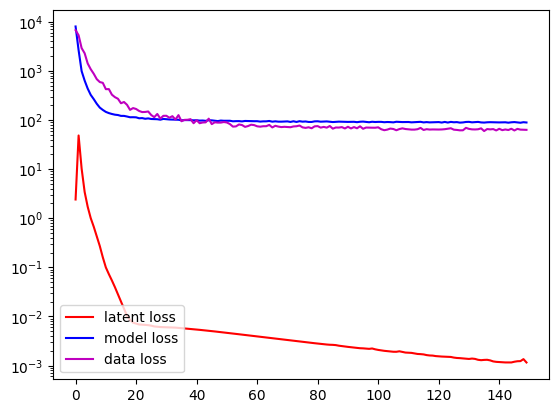

In [61]:
plt.semilogy(np.array(latent_loss_record),'r-',label='latent loss')
plt.semilogy(np.array(model_loss_record),'b-',label='model loss')
plt.semilogy(np.array(data_loss_record),'m-',label='data loss')
plt.legend(loc='lower left')

In [62]:
X_test_data.shape

(5000, 50)

In [63]:
val_ind = 2600
data = tf.constant(X_test_data[val_ind,:].reshape(1,-1))

In [64]:
X_test_model[val_ind,:,].shape

(1800,)

In [65]:
tf.random.set_seed(42)
number_gaussian_realization = 500
codings = tf.random.normal(shape=[number_gaussian_realization,coding_size]) # generate 200 realizations of Gaussian noise.
data_multiple = tf.tile(data,tf.constant([number_gaussian_realization,1])) # replicate gravity data 200 times and store them in a matrix with 200 rows.
predicted_model = variational_decoder([codings,data_multiple])

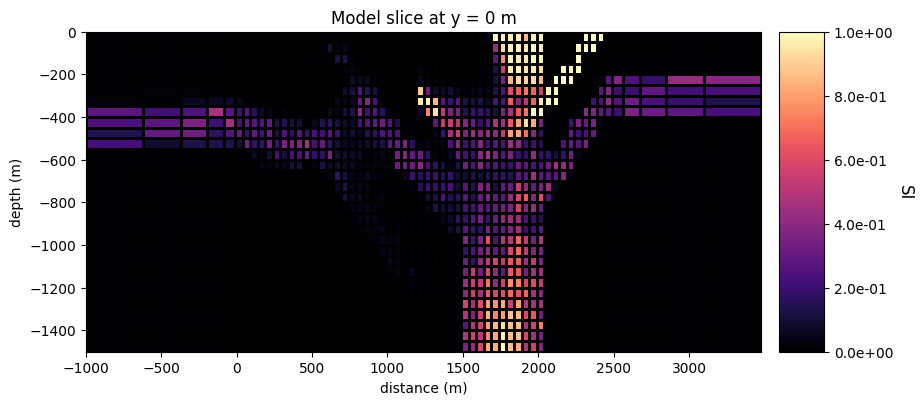

In [66]:
fig = plt.figure(figsize=(9, 4))

ax1 = fig.add_axes([0.08, 0.1, 0.75, 0.8])
mesh.plot_slice(
    plotting_map * np.squeeze(predicted_model[100,:]),
    normal="Y",
    ax=ax1,
    ind=int(mesh.shape_cells[1] / 2),
    grid=True,
    clim=(0,1),
    pcolor_opts={"cmap": "magma"},
)
ax1.set_title("Model slice at y = 0 m")
ax1.set_xlabel('distance (m)')
ax1.set_ylabel('depth (m)')

ax2 = fig.add_axes([0.85, 0.1, 0.05, 0.8])
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
cbar = matplotlib.colorbar.ColorbarBase(
    ax2, norm=norm, orientation="vertical", cmap=matplotlib.cm.magma, format="%.1e"
)
cbar.set_label("SI", rotation=270, labelpad=15, size=12)

plt.show()

In [67]:
std_model = np.std(np.array(predicted_model),axis=0)
std_model.shape

(1800,)

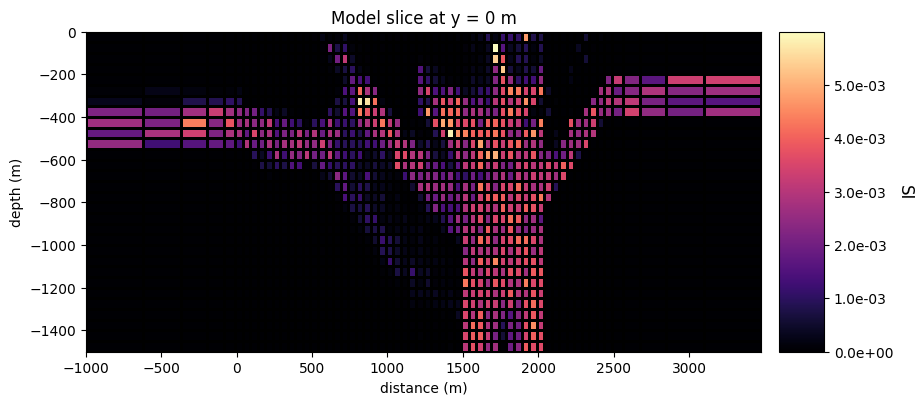

In [68]:
fig = plt.figure(figsize=(9, 4))

ax1 = fig.add_axes([0.08, 0.1, 0.75, 0.8])
mesh.plot_slice(
    plotting_map * std_model,
    normal="Y",
    ax=ax1,
    ind=int(mesh.shape_cells[1] / 2),
    grid=True,
    clim=(np.min(std_model),np.max(std_model)),
    pcolor_opts={"cmap": "magma"},
)
ax1.set_title("Model slice at y = 0 m")
ax1.set_xlabel('distance (m)')
ax1.set_ylabel('depth (m)')

ax2 = fig.add_axes([0.85, 0.1, 0.05, 0.8])
norm = matplotlib.colors.Normalize(vmin=np.min(std_model), vmax=np.max(std_model))
cbar = matplotlib.colorbar.ColorbarBase(
    ax2, norm=norm, orientation="vertical", cmap=matplotlib.cm.magma, format="%.1e"
)
cbar.set_label("SI", rotation=270, labelpad=15, size=12)

plt.show()

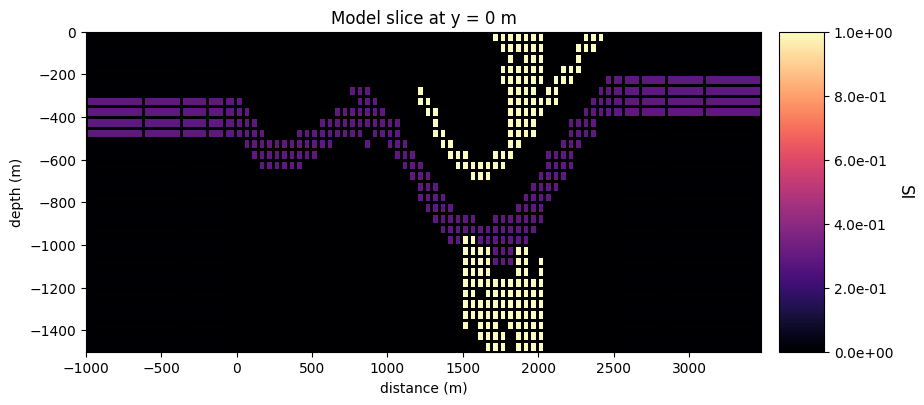

In [69]:
fig = plt.figure(figsize=(9, 4))

ax1 = fig.add_axes([0.08, 0.1, 0.75, 0.8])
mesh.plot_slice(
    plotting_map * np.squeeze(X_test_model[val_ind,:]),
    normal="Y",
    ax=ax1,
    ind=int(mesh.shape_cells[1] / 2),
    grid=True,
    clim=(0,1),
    pcolor_opts={"cmap": "magma"},
)
ax1.set_title("Model slice at y = 0 m")
ax1.set_xlabel('distance (m)')
ax1.set_ylabel('depth (m)')

ax2 = fig.add_axes([0.85, 0.1, 0.05, 0.8])
norm = matplotlib.colors.Normalize(vmin=0, vmax=1)
cbar = matplotlib.colorbar.ColorbarBase(
    ax2, norm=norm, orientation="vertical", cmap=matplotlib.cm.magma, format="%.1e"
)
cbar.set_label("SI", rotation=270, labelpad=15, size=12)

plt.show()

In [70]:
predicted_data = np.zeros([number_gaussian_realization,len(rxLoc)])
for i in range(number_gaussian_realization):
  predicted_data[i,:] = simulation.dpred(np.squeeze(predicted_model[i,:]*0.07))

In [71]:
predicted_data.shape

(500, 50)

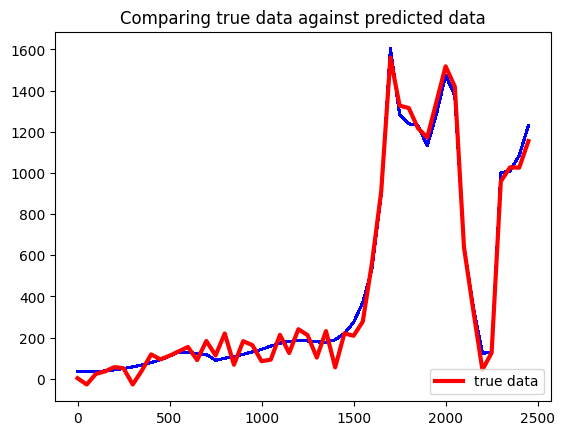

In [72]:
for k in np.arange(predicted_data.shape[0]):
  plt.plot(rxLoc[:,0],predicted_data[i,:],'b-')
plt.plot(rxLoc[:,0],np.squeeze(data),'r-',linewidth=3,label='true data')
plt.title('Comparing true data against predicted data')
plt.legend(loc='lower right')